<a href="https://colab.research.google.com/github/TimAdam000/mma-3001-occupancy-forecasting/blob/main/notebooks/occupancy_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/TimAdam000/MMA3001_Project


Cloning into 'MMA3001_Project'...


In [2]:
from google.colab import files
uploaded = files.upload()


In [3]:
import zipfile
import os

zip_path = '/content/5occupancySensor_MayToDec2024_9MRows.zip'
extract_path = '/content/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print("Extraction complete!")
    print("Files in directory:", os.listdir(extract_path))

Extraction complete!
Files in directory: ['.config', 'MMA3001_Project', '5occupancySensor_MayToDec2024_9MRows.csv', 'Screenshot (554).png', 'Screenshot (568).png', '5occupancySensor_MayToDec2024_9MRows.zip', 'Sensor ID and Locations.xlsx', 'drive', '5EnvSensor_MayToDec2024_180kRows.csv', 'sample_data']


In [4]:
import pandas as pd

# Path to the extracted CSV file
csv_path = '/content/5occupancySensor_MayToDec2024_9MRows.csv'

try:
    # Reading the CSV file
    df_occupancy = pd.read_csv(csv_path)
    print("Successfully loaded '5occupancySensor_MayToDec2024_9MRows.csv'!")
    print(f"DataFrame shape: {df_occupancy.shape}")
    display(df_occupancy.head())
except Exception as e:
    print(f"Could not load the CSV file: {e}")

Successfully loaded '5occupancySensor_MayToDec2024_9MRows.csv'!
DataFrame shape: (9091732, 8)


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-24 00:36:52+11,2023-11-24 00:36:52+11,NotOccupied
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,CurrentlyOccupied
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,NotOccupied
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,RecentlyOccupied
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,CurrentlyOccupied


In [5]:
import pandas as pd

# Load and display the Excel file you uploaded
file_path = '/content/Sensor ID and Locations.xlsx'
try:
    df_sensors = pd.read_excel(file_path)
    print("Successfully loaded 'Sensor ID and Locations.xlsx'!")
    display(df_sensors.head())
except Exception as e:
    print(f"Could not load the Excel file: {e}")

Successfully loaded 'Sensor ID and Locations.xlsx'!


,Building,Floor/Room,Area,Physical Label,Sensor,ID
0,60,1-PS01,Corridor,ES1104,Env,6012003000486
1,69,1-PS02,Breakout,ES2113,Env,6012003000882
2,60,1.40,Board Room,ES1102,Env,6012003000462
3,60,1.41,Open Office,ES1110,Env,6012003000424
4,60,1.41A,Focus Room 1,ES1101,Env,6012003000448


In [6]:
import pandas as pd

# Path to the environmental sensor data
env_csv_path = '/content/5EnvSensor_MayToDec2024_180kRows.csv'

try:
    df_env = pd.read_csv(env_csv_path)
    print("Successfully loaded '5EnvSensor_MayToDec2024_180kRows.csv'!")
    print(f"DataFrame shape: {df_env.shape}")
    display(df_env.head())
except Exception as e:
    print(f"Could not load the environmental sensor CSV file: {e}")

Successfully loaded '5EnvSensor_MayToDec2024_180kRows.csv'!
DataFrame shape: (179447, 8)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [7]:
import os, json
import numpy as np, pandas as pd

DATA_DIR = '/content'
OCC_FILE = '5occupancySensor_MayToDec2024_9MRows.csv'   # or .csv if unzipped
ENV_FILE = '5EnvSensor_MayToDec2024_180kRows.csv'       # or .csv if unzipped
MAP_FILE = 'Sensor ID and Locations.xlsx'

# Check the files are where we expect before doing anything heavy
print(os.listdir(DATA_DIR))
for f in (OCC_FILE, ENV_FILE, MAP_FILE):
    assert os.path.exists(os.path.join(DATA_DIR, f)), f"Not found in {DATA_DIR}: {f}"

BIN = '15min'
TZ = 'Australia/Melbourne'
OCCUPIED_STATES = {'CurrentlyOccupied'}   # add 'RecentlyOccupied' if you decide it counts
START, END = None, None                   # e.g. '2024-05-01', '2025-01-01'
MAX_FFILL_BINS = 8                        # carry last known status forward up to 2 h

# ---- Lookup: occupancy SpaceId -> room name
sheets = pd.read_excel(os.path.join(DATA_DIR, MAP_FILE), sheet_name=None, dtype=str)
env_map, occ_map = list(sheets.values())[0], list(sheets.values())[1]
space_to_room = occ_map.dropna(subset=['SpaceId']).groupby('SpaceId')['Floor/Room'].first().to_dict()

# ---- Occupancy: chunked aggregation of the event log to 15-min bins (UTC; local time added later)
STATUS_CODE = {'NotOccupied': 0, 'RecentlyOccupied': 1, 'CurrentlyOccupied': 2}
parts = []
reader = pd.read_csv(os.path.join(DATA_DIR, OCC_FILE),
                     usecols=['floorspaceid', 'occupancystatus', 'headcount', 'collecteddate'],
                     chunksize=1_000_000)
for ch in reader:
    t = pd.to_datetime(ch['collecteddate'], utc=True, errors='coerce')
    ch = ch.assign(t=t).dropna(subset=['t'])
    ch['bin'] = ch['t'].dt.floor(BIN)
    ch['status'] = ch['occupancystatus'].map(STATUS_CODE)
    ch = ch.dropna(subset=['status']).sort_values('t')
    parts.append(ch.groupby(['floorspaceid', 'bin']).agg(
        status=('status', 'last'), headcount=('headcount', 'max'),
        n_events=('status', 'size'), t_last=('t', 'max')).reset_index())

occ = pd.concat(parts).sort_values('t_last')
occ = occ.groupby(['floorspaceid', 'bin']).agg(
    status=('status', 'last'), headcount=('headcount', 'max'),
    n_events=('n_events', 'sum')).reset_index()

# ---- Regular time grid per space, carrying the last known status forward over short gaps
grids = []
for sid, g in occ.groupby('floorspaceid'):
    full = pd.date_range(g['bin'].min(), g['bin'].max(), freq=BIN)
    g = g.set_index('bin').reindex(full)
    g.index.name = 'timestamp'
    g['n_events'] = g['n_events'].fillna(0)
    g[['status', 'headcount']] = g[['status', 'headcount']].ffill(limit=MAX_FFILL_BINS)
    g['floorspaceid'] = sid
    grids.append(g.reset_index())
occ = pd.concat(grids, ignore_index=True)
occ['room'] = occ['floorspaceid'].map(space_to_room).fillna('unmapped_' + occ['floorspaceid'].str[:8])
occ = occ.dropna(subset=['status'])
occ['occupied'] = occ['status'].map({v: k for k, v in STATUS_CODE.items()}).isin(OCCUPIED_STATES).astype(int)
if START: occ = occ[occ['timestamp'] >= pd.Timestamp(START, tz=TZ).tz_convert('UTC')]
if END:   occ = occ[occ['timestamp'] <  pd.Timestamp(END,   tz=TZ).tz_convert('UTC')]
occ['local'] = occ['timestamp'].dt.tz_convert(TZ)

print(occ.shape)
print(occ.groupby('room')['occupied'].agg(rows='size', occupied_rate='mean'))
print(occ.groupby('room')['timestamp'].agg(['min', 'max']))

['.config', 'MMA3001_Project', '5occupancySensor_MayToDec2024_9MRows.csv', 'Screenshot (554).png', 'Screenshot (568).png', '5occupancySensor_MayToDec2024_9MRows.zip', 'Sensor ID and Locations.xlsx', 'drive', '5EnvSensor_MayToDec2024_180kRows.csv', 'sample_data']
(274014, 8)
                    rows  occupied_rate
room                                   
G.20               49161       0.475214
G.25               68422       0.378738
unmapped_0f3f37f8  67408       0.409877
unmapped_3e5a14df  20162       0.603561
unmapped_941f0352  68861       0.411844
                                        min                       max
room                                                                 
G.20              2024-03-03 04:00:00+00:00 2026-04-22 12:45:00+00:00
G.25              2024-03-03 04:00:00+00:00 2026-04-22 12:00:00+00:00
unmapped_0f3f37f8 2023-11-23 13:30:00+00:00 2026-04-22 13:00:00+00:00
unmapped_3e5a14df 2024-04-30 14:00:00+00:00 2024-12-30 12:00:00+00:00
unmapped_941f0352 2023-11

In [8]:
env = pd.read_csv(os.path.join(DATA_DIR, ENV_FILE), usecols=['sensorid', 'jsondata'], dtype={'sensorid': str})

def parse(js):
    out = {}
    try:
        for item in json.loads(js):
            v = item['values'][0]
            out[item['variable']['name']] = v['value']
            out['_t'] = v['time']
    except Exception:
        return None
    return out

parsed = env['jsondata'].map(parse)
ok = parsed.notna()
wide = pd.DataFrame(parsed[ok].tolist(), index=env.index[ok])
env = pd.concat([env.loc[ok, ['sensorid']], wide], axis=1)
env['timestamp'] = pd.to_datetime(env['_t'], unit='s', utc=True).dt.floor(BIN)
env = env.drop(columns='_t')
ENV_NUM = [c for c in env.columns if c not in ('sensorid', 'timestamp')]
env = env.groupby(['sensorid', 'timestamp'])[ENV_NUM].mean().reset_index()

# Excel stores IDs as numbers; convert back to the 13-digit strings used in the CSV
id_to_room = (env_map.assign(ID=env_map['ID'].astype(float).astype('int64').astype(str))
              .drop_duplicates('ID').set_index('ID')['Floor/Room'].to_dict())
env['room'] = env['sensorid'].map(id_to_room)

print(env.groupby('sensorid').agg(room=('room', 'first'), start=('timestamp', 'min'),
                                  end=('timestamp', 'max'), bins=('timestamp', 'size')))
print("Rooms with BOTH env and occupancy data:", set(env['room'].dropna()) & set(occ['room']))
print("Duplicate IDs in lookup:\n", env_map[env_map['ID'].duplicated(keep=False)])

               room                     start                       end  bins
sensorid                                                                     
6012002000227  None 2023-12-11 05:00:00+00:00 2023-12-11 05:00:00+00:00     1
6012002000241  None 2023-12-11 05:45:00+00:00 2023-12-11 05:45:00+00:00     1
6012002000326  None 2023-12-11 05:00:00+00:00 2023-12-11 05:00:00+00:00     1
6012002000777  None 2023-05-05 22:30:00+00:00 2023-05-05 22:30:00+00:00     1
6012002000869  G.38 2024-02-29 06:00:00+00:00 2024-06-13 17:45:00+00:00  9650
Rooms with BOTH env and occupancy data: set()
Duplicate IDs in lookup:
    Building Floor/Room           Area Physical Label Sensor             ID
65       69       G.52       Workshop         ES2G14    Env  6012003000691
75       69       G.61  East Entrance         ES2G01    Env  6012003000691


In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

HORIZON_BINS = 4                      # 4 x 15 min = predict 1 hour ahead
STEP = pd.Timedelta(BIN)

d = occ[['room', 'timestamp', 'local', 'occupied', 'headcount']].sort_values(['room', 'timestamp']).reset_index(drop=True)

# Target = occupancy HORIZON_BINS ahead, matched on real timestamps (gaps give NaN, not a wrong row)
tgt = d[['room', 'timestamp', 'occupied']].copy()
tgt['timestamp'] -= HORIZON_BINS * STEP
d = d.merge(tgt.rename(columns={'occupied': 'target'}), on=['room', 'timestamp'], how='left')

# Same time last week (past only)
wk = d[['room', 'timestamp', 'occupied']].copy()
wk['timestamp'] += pd.Timedelta(days=7)
d = d.merge(wk.rename(columns={'occupied': 'occ_last_week'}), on=['room', 'timestamp'], how='left')

# Past-only rolling occupancy
d['occ_mean_1h'] = d.groupby('room')['occupied'].transform(lambda s: s.rolling(4,  min_periods=1).mean())
d['occ_mean_4h'] = d.groupby('room')['occupied'].transform(lambda s: s.rolling(16, min_periods=1).mean())

# Time features from LOCAL Melbourne time
hr = d['local'].dt.hour + d['local'].dt.minute / 60
d['hour_sin'] = np.sin(2 * np.pi * hr / 24)
d['hour_cos'] = np.cos(2 * np.pi * hr / 24)
d['hour'] = d['local'].dt.hour
d['dayofweek'] = d['local'].dt.dayofweek
d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
d['room_code'] = d['room'].astype('category').cat.codes

FEATURES = ['occupied', 'headcount', 'occ_mean_1h', 'occ_mean_4h', 'occ_last_week',
            'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend', 'room_code']
d = d.dropna(subset=['target'] + [f for f in FEATURES if f != 'occ_last_week']).reset_index(drop=True)
d['target'] = d['target'].astype(int)
d['occ_last_week'] = d['occ_last_week'].fillna(-1)     # -1 = unknown

# Chronological 60/20/20 split
t1, t2 = d['timestamp'].quantile([0.6, 0.8])
train = d[d.timestamp <= t1]
val   = d[(d.timestamp > t1) & (d.timestamp <= t2)]
test  = d[d.timestamp > t2]
for n, p in [('train', train), ('val', val), ('test', test)]:
    print(f"{n:5s} {len(p):7d} rows {p.timestamp.min():%Y-%m-%d} -> {p.timestamp.max():%Y-%m-%d} occupied={p.target.mean():.2%}")

def report(name, y, p):
    print(f"{name:30s} P={precision_score(y,p,zero_division=0):.3f} R={recall_score(y,p,zero_division=0):.3f} "
          f"F1={f1_score(y,p,zero_division=0):.3f} Acc={(y==p).mean():.3f}")

report('A: majority class',            val.target, np.full(len(val), train.target.mode()[0]))
report('B: persistence (same as now)', val.target, val['occupied'])
how = train.assign(k=train.dayofweek * 24 + train.hour).groupby('k').target.mean().ge(0.5).astype(int)
report('C: hour-of-week rule',         val.target, (val.dayofweek * 24 + val.hour).map(how).fillna(0).astype(int))

train  155801 rows 2023-11-23 -> 2025-04-25 occupied=46.05%
val     51935 rows 2025-04-25 -> 2025-10-16 occupied=44.06%
test    51933 rows 2025-10-16 -> 2026-04-22 occupied=38.96%
A: majority class              P=0.000 R=0.000 F1=0.000 Acc=0.559
B: persistence (same as now)   P=0.720 R=0.735 F1=0.727 Acc=0.757
C: hour-of-week rule           P=0.716 R=0.682 F1=0.699 Acc=0.741


,n_estimators,max_depth,min_samples_leaf,val_F1,train_F1,fit_s
5,100,20,50,0.764144,0.781456,10.383490
11,200,20,50,0.763832,0.781423,22.615679
8,200,12,10,0.763496,0.792249,24.760102
2,100,12,10,0.763460,0.792499,12.828869
3,100,12,50,0.762271,0.779896,12.237860
9,200,12,50,0.762263,0.780041,22.889397
4,100,20,10,0.761922,0.807848,15.287040
10,200,20,10,0.761856,0.808321,30.192436


Best settings: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 50}

=== TEST SET (final, unseen later period) ===
A: majority class                  P=0.000 R=0.000 F1=0.000 Acc=0.610
B: persistence (same as now)       P=0.683 R=0.698 F1=0.691 Acc=0.756
C: hour-of-week rule               P=0.634 R=0.694 F1=0.662 Acc=0.725
D: logistic regression             P=0.725 R=0.700 F1=0.712 Acc=0.780
Random Forest                      P=0.730 R=0.723 F1=0.727 Acc=0.788

=== Overfitting check (Random Forest F1) ===
train F1=0.781
val   F1=0.764
test  F1=0.727

Confusion matrix, test (rows = actual 0/1, cols = predicted 0/1):
[[26303  5396]
 [ 5612 14622]]


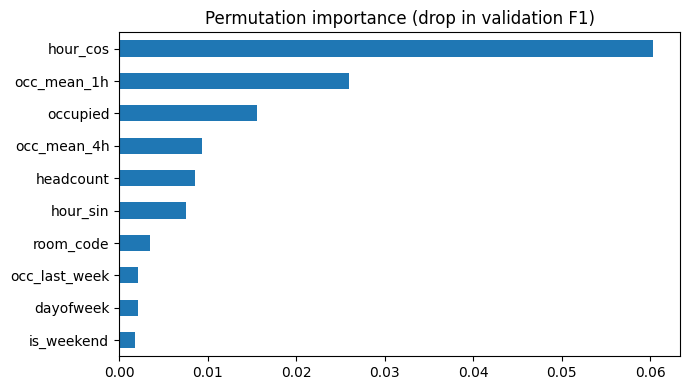

hour_cos         0.0604
occ_mean_1h      0.0260
occupied         0.0155
occ_mean_4h      0.0094
headcount        0.0086
hour_sin         0.0076
room_code        0.0035
occ_last_week    0.0021
dayofweek        0.0021
is_weekend       0.0017
dtype: float64


In [10]:
import matplotlib.pyplot as plt
import time, itertools
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
Xtr, ytr = train[FEATURES], train['target']
Xva, yva = val[FEATURES],   val['target']
Xte, yte = test[FEATURES],  test['target']

def scores(y, p):
    return dict(P=precision_score(y, p, zero_division=0), R=recall_score(y, p, zero_division=0),
                F1=f1_score(y, p, zero_division=0), Acc=(y == p).mean())

# ---- Tune a small grid on the VALIDATION set only
grid = list(itertools.product([100, 200], [6, 12, 20], [10, 50]))   # n_estimators, max_depth, min_samples_leaf
rows = []
for n, md, leaf in grid:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=n, max_depth=md, min_samples_leaf=leaf,
                                n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
    s = scores(yva, rf.predict(Xva))
    rows.append(dict(n_estimators=n, max_depth=md, min_samples_leaf=leaf, val_F1=s['F1'],
                     train_F1=f1_score(ytr, rf.predict(Xtr)), fit_s=time.time() - t0))
tune = pd.DataFrame(rows).sort_values('val_F1', ascending=False)
display(tune.head(8))
best = tune.iloc[0]
BEST = dict(n_estimators=int(best.n_estimators), max_depth=int(best.max_depth), min_samples_leaf=int(best.min_samples_leaf))
print("Best settings:", BEST)

# ---- Final model: train on TRAIN only; the test set is used once, here
rf = RandomForestClassifier(**BEST, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)

def line(name, y, p):
    s = scores(y, p); print(f"{name:34s} P={s['P']:.3f} R={s['R']:.3f} F1={s['F1']:.3f} Acc={s['Acc']:.3f}")

print("\n=== TEST SET (final, unseen later period) ===")
how = train.assign(k=train.dayofweek * 24 + train.hour).groupby('k').target.mean().ge(0.5).astype(int)
line('A: majority class',            yte, np.full(len(test), train.target.mode()[0]))
line('B: persistence (same as now)', yte, test['occupied'])
line('C: hour-of-week rule',         yte, (test.dayofweek * 24 + test.hour).map(how).fillna(0).astype(int))
line('D: logistic regression',       yte, lr.predict(Xte))
line('Random Forest',                yte, rf.predict(Xte))

print("\n=== Overfitting check (Random Forest F1) ===")
for n, X, y in [('train', Xtr, ytr), ('val', Xva, yva), ('test', Xte, yte)]:
    print(f"{n:5s} F1={f1_score(y, rf.predict(X)):.3f}")

print("\nConfusion matrix, test (rows = actual 0/1, cols = predicted 0/1):")
print(confusion_matrix(yte, rf.predict(Xte)))

# ---- Feature importance: permutation importance on validation F1
pi = permutation_importance(rf, Xva, yva, scoring='f1', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind='barh', figsize=(7, 4), title='Permutation importance (drop in validation F1)')
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4))

/tmp/ipykernel_69681/1225916000.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_room = test.groupby('room').apply(lambda g: pd.Series(dict(


,n,occupied_rate,F1,persistence_F1,error_rate
room,,,,,
G.20,10294.0,0.498,0.789,0.765,0.212
G.25,16552.0,0.320,0.509,0.539,0.281
unmapped_0f3f37f8,11631.0,0.370,0.758,0.682,0.190
unmapped_941f0352,13456.0,0.409,0.827,0.773,0.145


/tmp/ipykernel_69681/1225916000.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_hour = test.groupby('hour').apply(lambda g: pd.Series(dict(


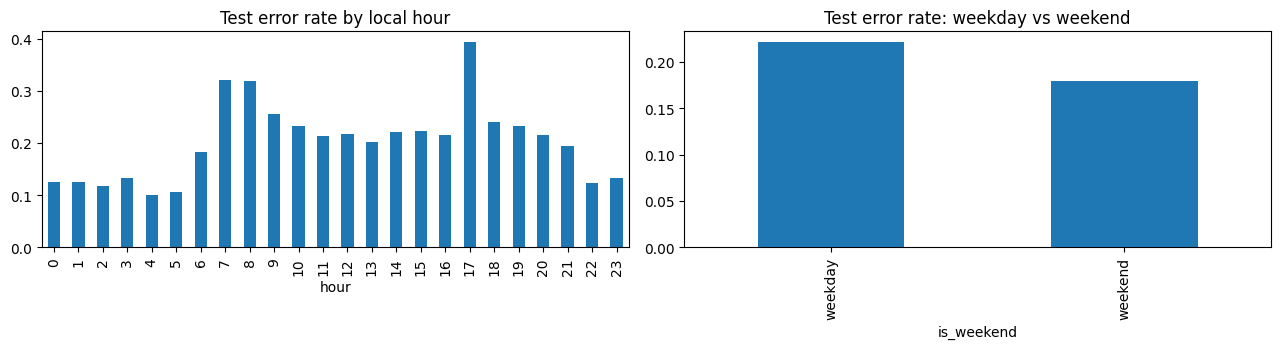

,removed,val_F1,change,fit_s
0,(none: all features),0.7641,0.0000,9.4271
1,"current state (occupied, headcount)",0.7573,-0.0069,9.0200
2,"rolling history (1 h, 4 h)",0.7522,-0.0119,6.5217
3,same time last week,0.7633,-0.0008,11.5654
4,time of day/week,0.7384,-0.0258,4.9375
5,room identity,0.7607,-0.0035,11.5799


In [11]:
# ---- Error analysis on the TEST set
test = test.copy(); test['pred'] = rf.predict(Xte); test['wrong'] = (test['pred'] != test['target']).astype(int)

by_room = test.groupby('room').apply(lambda g: pd.Series(dict(
    n=len(g), occupied_rate=g.target.mean(), F1=f1_score(g.target, g.pred, zero_division=0),
    persistence_F1=f1_score(g.target, g.occupied, zero_division=0), error_rate=g.wrong.mean())))
display(by_room.round(3))

by_hour = test.groupby('hour').apply(lambda g: pd.Series(dict(
    error_rate=g.wrong.mean(), occupied_rate=g.target.mean())))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
by_hour['error_rate'].plot(kind='bar', ax=ax[0], title='Test error rate by local hour')
test.groupby('is_weekend')['wrong'].mean().rename({0: 'weekday', 1: 'weekend'}).plot(kind='bar', ax=ax[1], title='Test error rate: weekday vs weekend')
plt.tight_layout(); plt.show()

# ---- Sensitivity analysis: remove one feature group, retrain, score on VALIDATION (test stays untouched)
GROUPS = {
    'current state (occupied, headcount)': ['occupied', 'headcount'],
    'rolling history (1 h, 4 h)':          ['occ_mean_1h', 'occ_mean_4h'],
    'same time last week':                 ['occ_last_week'],
    'time of day/week':                    ['hour_sin', 'hour_cos', 'dayofweek', 'is_weekend'],
    'room identity':                       ['room_code'],
}
def fit_eval(feats):
    t0 = time.time()
    m = RandomForestClassifier(**BEST, n_jobs=-1, random_state=RANDOM_STATE).fit(train[feats], ytr)
    return f1_score(yva, m.predict(val[feats])), time.time() - t0

full_f1, full_t = fit_eval(FEATURES)
res = [dict(removed='(none: all features)', val_F1=full_f1, change=0.0, fit_s=full_t)]
for name, cols in GROUPS.items():
    f1v, secs = fit_eval([f for f in FEATURES if f not in cols])
    res.append(dict(removed=name, val_F1=f1v, change=f1v - full_f1, fit_s=secs))
display(pd.DataFrame(res).round(4))

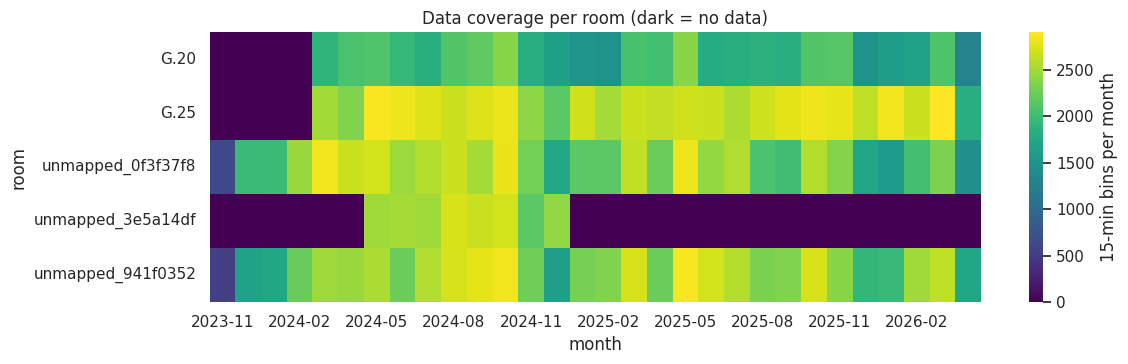

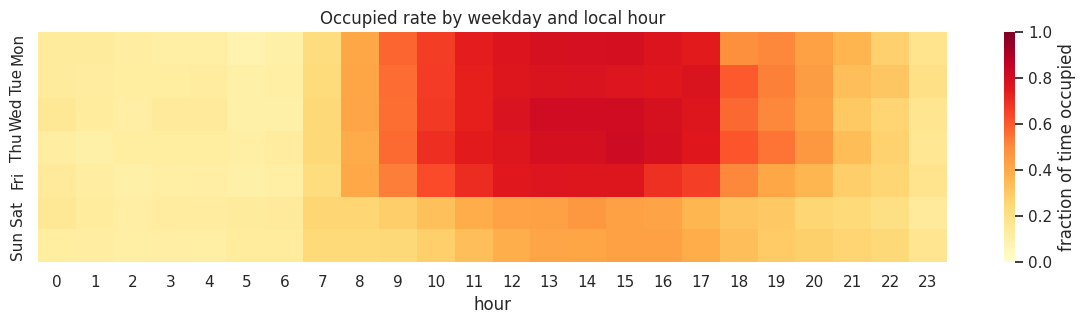

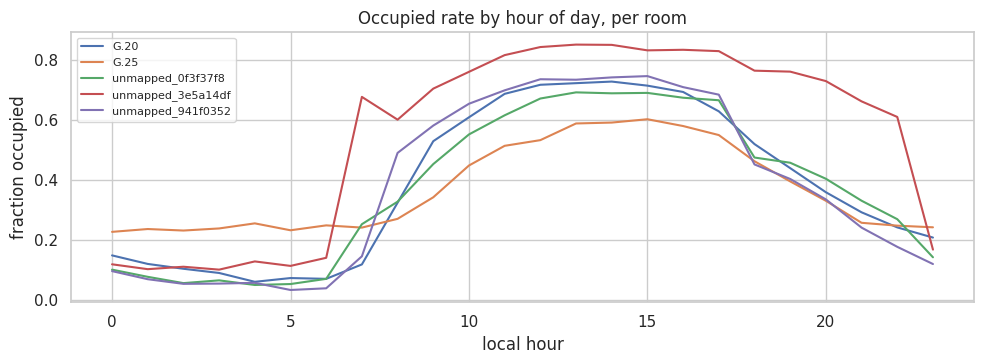

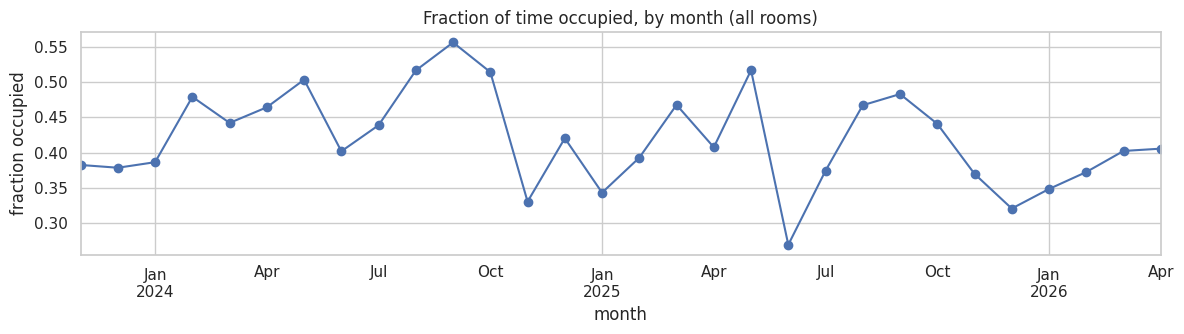

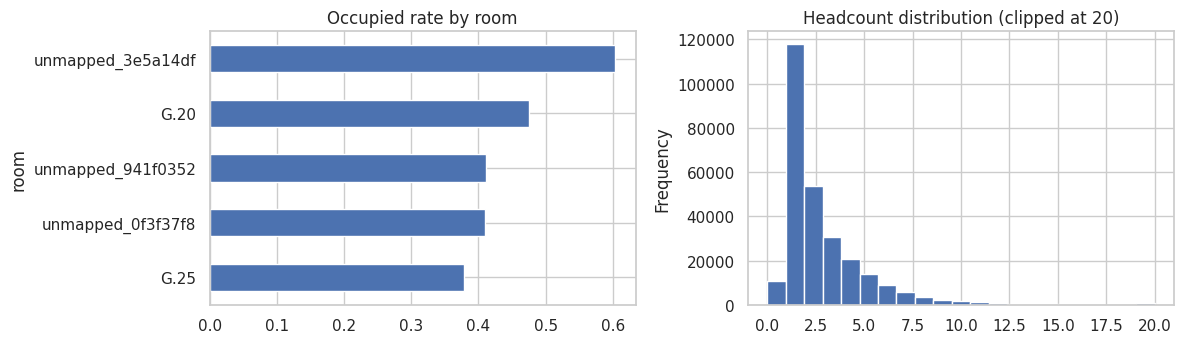

status,NotOccupied,RecentlyOccupied,CurrentlyOccupied
room,,,
G.20,0.505,0.020,0.475
G.25,0.581,0.040,0.379
unmapped_0f3f37f8,0.535,0.055,0.410
unmapped_3e5a14df,0.364,0.032,0.604
unmapped_941f0352,0.553,0.035,0.412


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

e = occ.copy()
e['hour'] = e['local'].dt.hour
e['dow'] = e['local'].dt.dayofweek
e['month'] = e['local'].dt.tz_localize(None).dt.to_period('M').dt.to_timestamp()

# 3.1 Data coverage: how many 15-min bins each room has per month (dark = no data)
cov = e.groupby(['room', 'month']).size().unstack(0).fillna(0)
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(cov.T, cmap='viridis', ax=ax, cbar_kws={'label': '15-min bins per month'},
            xticklabels=[m.strftime('%Y-%m') if i % 3 == 0 else '' for i, m in enumerate(cov.index)])
ax.set_title('Data coverage per room (dark = no data)'); ax.set_xlabel('month'); plt.tight_layout(); plt.show()

# 3.2 Occupied rate by hour x weekday (all rooms)
pivot = e.pivot_table(index='dow', columns='hour', values='occupied', aggfunc='mean')
pivot.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(pivot, cmap='YlOrRd', ax=ax, vmin=0, vmax=1, cbar_kws={'label': 'fraction of time occupied'})
ax.set_title('Occupied rate by weekday and local hour'); plt.tight_layout(); plt.show()

# 3.3 Daily profile for each room
fig, ax = plt.subplots(figsize=(10, 3.8))
for r, g in e.groupby('room'):
    g.groupby('hour')['occupied'].mean().plot(ax=ax, label=r)
ax.set(title='Occupied rate by hour of day, per room', ylabel='fraction occupied', xlabel='local hour'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# 3.4 Occupied rate over the months (semester / holiday pattern)
fig, ax = plt.subplots(figsize=(12, 3.5))
e.groupby('month')['occupied'].mean().plot(ax=ax, marker='o')
ax.set(title='Fraction of time occupied, by month (all rooms)', ylabel='fraction occupied'); plt.tight_layout(); plt.show()

# 3.5 Room comparison and headcount distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
e.groupby('room')['occupied'].mean().sort_values().plot(kind='barh', ax=ax[0], title='Occupied rate by room')
e['headcount'].clip(upper=20).plot(kind='hist', bins=21, ax=ax[1], title='Headcount distribution (clipped at 20)')
plt.tight_layout(); plt.show()

# 3.6 Status mix per room (Not / Recently / Currently occupied)
mix = e.groupby('room')['status'].value_counts(normalize=True).unstack().rename(
    columns={0: 'NotOccupied', 1: 'RecentlyOccupied', 2: 'CurrentlyOccupied'})
display(mix.round(3))

In [13]:
import time, pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score

def build_dataset(occ_in, horizon_bins=4, include_recent=False):
    """Rebuild features, target and chronological split from the binned occupancy table.

    horizon_bins: forecast horizon in 15-minute bins (4 = 1 hour ahead).
    include_recent: if True, 'RecentlyOccupied' also counts as occupied.
    Returns (train, val, test) DataFrames using the global FEATURES list.
    """
    step = pd.Timedelta(BIN)
    x = occ_in[['room', 'timestamp', 'local', 'status', 'headcount']].copy()
    x['occupied'] = (x['status'] >= 1).astype(int) if include_recent else (x['status'] == 2).astype(int)
    x = x.sort_values(['room', 'timestamp']).reset_index(drop=True)

    tgt = x[['room', 'timestamp', 'occupied']].copy(); tgt['timestamp'] -= horizon_bins * step
    x = x.merge(tgt.rename(columns={'occupied': 'target'}), on=['room', 'timestamp'], how='left')
    wk = x[['room', 'timestamp', 'occupied']].copy(); wk['timestamp'] += pd.Timedelta(days=7)
    x = x.merge(wk.rename(columns={'occupied': 'occ_last_week'}), on=['room', 'timestamp'], how='left')
    x['occ_mean_1h'] = x.groupby('room')['occupied'].transform(lambda s: s.rolling(4, min_periods=1).mean())
    x['occ_mean_4h'] = x.groupby('room')['occupied'].transform(lambda s: s.rolling(16, min_periods=1).mean())
    hr = x['local'].dt.hour + x['local'].dt.minute / 60
    x['hour_sin'] = np.sin(2 * np.pi * hr / 24); x['hour_cos'] = np.cos(2 * np.pi * hr / 24)
    x['hour'] = x['local'].dt.hour; x['dayofweek'] = x['local'].dt.dayofweek
    x['is_weekend'] = (x['dayofweek'] >= 5).astype(int)
    x['room_code'] = x['room'].astype('category').cat.codes
    x = x.dropna(subset=['target'] + [f for f in FEATURES if f != 'occ_last_week']).reset_index(drop=True)
    x['target'] = x['target'].astype(int); x['occ_last_week'] = x['occ_last_week'].fillna(-1)
    t1, t2 = x['timestamp'].quantile([0.6, 0.8])
    return x[x.timestamp <= t1], x[(x.timestamp > t1) & (x.timestamp <= t2)], x[x.timestamp > t2]

# Sanity check: the function must reproduce the datasets from Cell 3
tr0, va0, te0 = build_dataset(occ, 4, False)
print("Reproduces Cell 3?", len(tr0) == len(train), len(va0) == len(val), len(te0) == len(test))

# ---------- 7a. Forecast-horizon sensitivity (scored on VALIDATION; test stays untouched) ----------
rows = []
for name, h in [('15 min', 1), ('1 hour', 4), ('4 hours', 16)]:
    tr, va, _ = build_dataset(occ, h, False)
    m = RandomForestClassifier(**BEST, n_jobs=-1, random_state=RANDOM_STATE).fit(tr[FEATURES], tr['target'])
    f_rf = f1_score(va['target'], m.predict(va[FEATURES]))
    f_pe = f1_score(va['target'], va['occupied'])
    rows.append(dict(horizon=name, RF_F1=f_rf, persistence_F1=f_pe, RF_gain=f_rf - f_pe, val_rows=len(va)))
horizon_res = pd.DataFrame(rows); display(horizon_res.round(3))

# ---------- 7b. Label definition: does "RecentlyOccupied" count as occupied? (1 h ahead) ----------
rows = []
for name, inc in [('Occupied = Currently only', False), ('Occupied = Currently or Recently', True)]:
    tr, va, _ = build_dataset(occ, 4, inc)
    m = RandomForestClassifier(**BEST, n_jobs=-1, random_state=RANDOM_STATE).fit(tr[FEATURES], tr['target'])
    p = m.predict(va[FEATURES])
    rows.append(dict(label=name, occupied_rate=va['target'].mean(), precision=precision_score(va['target'], p),
                     recall=recall_score(va['target'], p), RF_F1=f1_score(va['target'], p),
                     persistence_F1=f1_score(va['target'], va['occupied'])))
label_res = pd.DataFrame(rows); display(label_res.round(3))

# ---------- 7c. Runtime and memory ----------
rows = []
for n in [10, 50, 100, 200]:
    t0 = time.time(); m = RandomForestClassifier(**{**BEST, 'n_estimators': n}, n_jobs=-1, random_state=RANDOM_STATE).fit(train[FEATURES], train['target'])
    fit_s = time.time() - t0
    t0 = time.time(); p = m.predict(val[FEATURES]); pred_s = time.time() - t0
    rows.append(dict(model=f'RandomForest n={n}', fit_s=fit_s, predict_s=pred_s,
                     us_per_row=1e6 * pred_s / len(val), model_MB=len(pickle.dumps(m)) / 1e6, val_F1=f1_score(val['target'], p)))
t0 = time.time(); lr_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[FEATURES], train['target']); fit_s = time.time() - t0
t0 = time.time(); p = lr_m.predict(val[FEATURES]); pred_s = time.time() - t0
rows.append(dict(model='Logistic regression', fit_s=fit_s, predict_s=pred_s, us_per_row=1e6 * pred_s / len(val),
                 model_MB=len(pickle.dumps(lr_m)) / 1e6, val_F1=f1_score(val['target'], p)))
runtime_res = pd.DataFrame(rows); display(runtime_res.round(4))
print(f"\nBinned occupancy table in memory: {occ.memory_usage(deep=True).sum() / 1e6:.1f} MB "
      f"({len(occ):,} rows) vs raw event log of 9,091,732 rows (~1.6 GB on disk)")

Reproduces Cell 3? True True True


,horizon,RF_F1,persistence_F1,RF_gain,val_rows
0,15 min,0.810,0.793,0.017,53990
1,1 hour,0.764,0.727,0.037,51935
2,4 hours,0.722,0.579,0.143,47700


,label,occupied_rate,precision,recall,RF_F1,persistence_F1
0,Occupied = Currently only,0.441,0.771,0.757,0.764,0.727
1,Occupied = Currently or Recently,0.482,0.791,0.782,0.786,0.752


,model,fit_s,predict_s,us_per_row,model_MB,val_F1
0,RandomForest n=10,1.7381,0.0517,0.9953,2.0659,0.7635
1,RandomForest n=50,4.2242,0.2368,4.5604,10.3019,0.7638
2,RandomForest n=100,10.7160,0.7750,14.9220,20.5515,0.7641
3,RandomForest n=200,20.2326,0.8375,16.1262,41.1437,0.7638
4,Logistic regression,0.2527,0.0105,0.2028,0.0016,0.7552



Binned occupancy table in memory: 55.2 MB (274,014 rows) vs raw event log of 9,091,732 rows (~1.6 GB on disk)
